# 03 Analisis Eksploratori (Exploratory Data Analysis - EDA)

## Hasil pembelajaran

Setelah notebook ini, Anda dapat:

- Membuat histogram untuk distribusi data numerik;
- Membandingkan grup menggunakan boxplot;
- Membuat scatter plot untuk melihat hubungan dua variabel;
- Membuat bar chart untuk frekuensi kategoris;
- Menulis interpretasi visual dengan hati-hati.

### Penanda Sel Kode
- `# RUN-NOW`: dapat langsung dijalankan.
- `# LEARNER-TASK`: ubah bagian bertanda [UBAH]/[ANDA TULIS], lalu jalankan.

## Apa itu EDA?

**Exploratory Data Analysis (EDA)** = "Bermain" dengan data melalui visualisasi dan ringkasan untuk:

1. **Memahami pola** - distribusi, trend, outlier
2. **Menemukan ide** - pertanyaan apa yang menarik?
3. **Merencanakan analisis** - metode apa yang cocok?
4. **Mengidentifikasi masalah** - ada yang aneh?

**Penting:** EDA bukan untuk menyimpulkan, tapi untuk mengeksplorasi.

## Impor library dan data

In [1]:
# RUN-NOW: Jalankan sel ini apa adanya.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Muat data bersih dari notebook sebelumnya (robust terhadap working directory)
candidate_paths = [
    Path("data/processed/student_performance_cleaned.csv"),
    Path("../data/processed/student_performance_cleaned.csv"),
    Path("/workspaces/metpen-ai-lab/data/processed/student_performance_cleaned.csv"),
]

cleaned_file = next((p for p in candidate_paths if p.exists()), None)
if cleaned_file is None:
    raise FileNotFoundError(
        "File data bersih tidak ditemukan. Jalankan notebook 02 atau periksa folder data/processed."
    )

df = pd.read_csv(cleaned_file)

# Set style untuk visualisasi yang lebih menarik
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print(f"Data dimuat dari: {cleaned_file.resolve()}")
print(f"Data dimuat: {df.shape[0]} baris × {df.shape[1]} kolom")

Data dimuat dari: /workspaces/metpen-ai-lab/notebooks/data/processed/student_performance_cleaned.csv
Data dimuat: 2000 baris × 20 kolom


## Chart 1: Histogram - Distribusi final_grade

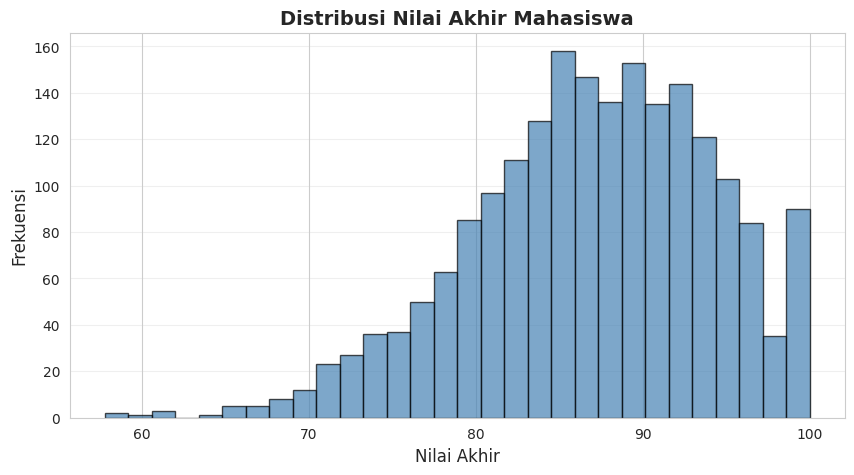

📊 Interpretasi:
  Mean (rata-rata): 86.91
  Median (tengah): 87.34
  Std Dev: 7.28


In [2]:
# RUN-NOW: Jalankan sel ini apa adanya.
plt.figure(figsize=(10, 5))
plt.hist(df['final_grade'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
plt.xlabel('Nilai Akhir', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.title('Distribusi Nilai Akhir Mahasiswa', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

print("📊 Interpretasi:")
print(f"  Mean (rata-rata): {df['final_grade'].mean():.2f}")
print(f"  Median (tengah): {df['final_grade'].median():.2f}")
print(f"  Std Dev: {df['final_grade'].std():.2f}")

### Apa histogram ini menunjukkan?

**Pola yang terlihat:**
- Distribusi nilai akhir mahasiswa
- Apakah distribution normal (bell curve)? Skewed?
- Di mana puncaknya (mode)?
- Ada outlier ekstrim?

**Mengapa histogram cocok:**
- Melihat bentuk distribusi data numerik
- Mengidentifikasi normalitas

**Hati-hati:**
- Banyak bin → terlalu detail, banyak noise
- Sedikit bin → terlalu simplified
- Jumlah histogram tergantung ukuran data dan pertanyaan Anda

## Chart 2: Boxplot - Membandingkan nilai akhir antar program

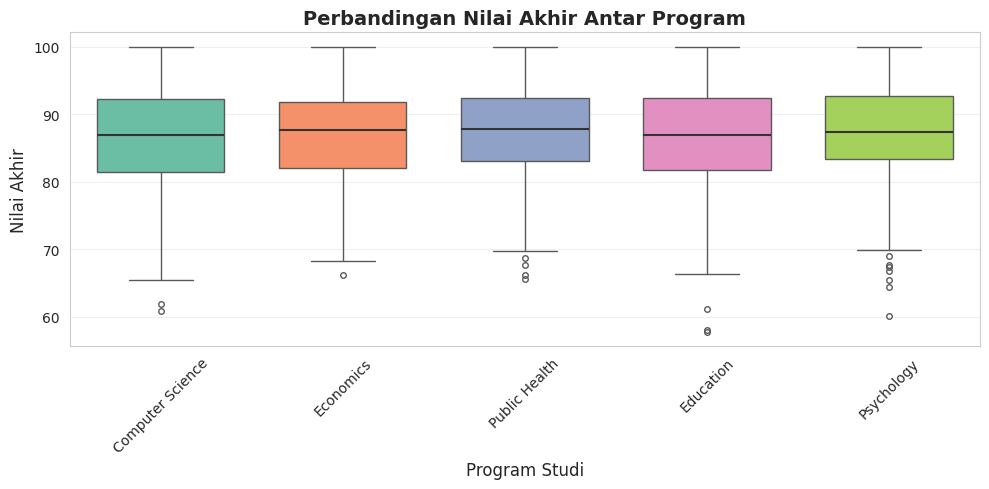

📊 Ringkasan per program:
                  count       mean       std    min      25%     50%      75%  \
program                                                                         
Computer Science  435.0  86.555632  7.384807  60.92  81.4750  86.890  92.2150   
Economics         415.0  86.896145  7.056395  66.16  81.9850  87.610  91.8100   
Education         453.0  86.599845  7.432495  57.80  81.8000  86.910  92.3400   
Psychology        399.0  87.377870  7.267842  60.11  83.3350  87.430  92.7300   
Public Health     298.0  87.265470  7.197959  65.60  83.1125  87.845  92.3575   

                    max  
program                  
Computer Science  100.0  
Economics         100.0  
Education         100.0  
Psychology        100.0  
Public Health     100.0  


In [3]:
# RUN-NOW: Jalankan sel ini apa adanya.
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="program",
    y="final_grade",
    hue="program",
    palette="Set2",
    legend=False,
    dodge=False,
    saturation=0.9,
    linewidth=1,
    width=0.7,
    showfliers=True,
    fliersize=4,
    whiskerprops={"linewidth": 1},
    capprops={"linewidth": 1},
    medianprops={"linewidth": 1.5, "color": "#333"},
)
plt.xlabel("Program Studi", fontsize=12)
plt.ylabel("Nilai Akhir", fontsize=12)
plt.title("Perbandingan Nilai Akhir Antar Program", fontsize=14, fontweight="bold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Ringkasan per program
print("📊 Ringkasan per program:")
print(df.groupby("program")["final_grade"].describe())

### Apa boxplot ini menunjukkan?

**Elemen boxplot:**
- **Kotak**: Range tengah 50% data (Q1-Q3)
- **Garis di kotak**: Median (Q2)
- **Whisker**: Batas data (±1.5×IQR)
- **Titik**: Outlier (di luar whisker)

**Pola yang dicari:**
- Program mana dengan median tertinggi/terendah?
- Program mana dengan variasi terbesar/terkecil?
- Ada outlier ekstrim di program tertentu?

**Caution:**
- Boxplot tidak menunjukkan distribusi detail
- Bimodal data tidak terlihat jelas di boxplot
- Gunakan dengan histogram untuk gambaran lengkap

## Chart 3: Scatter plot - Hubungan attendance_rate dan final_grade

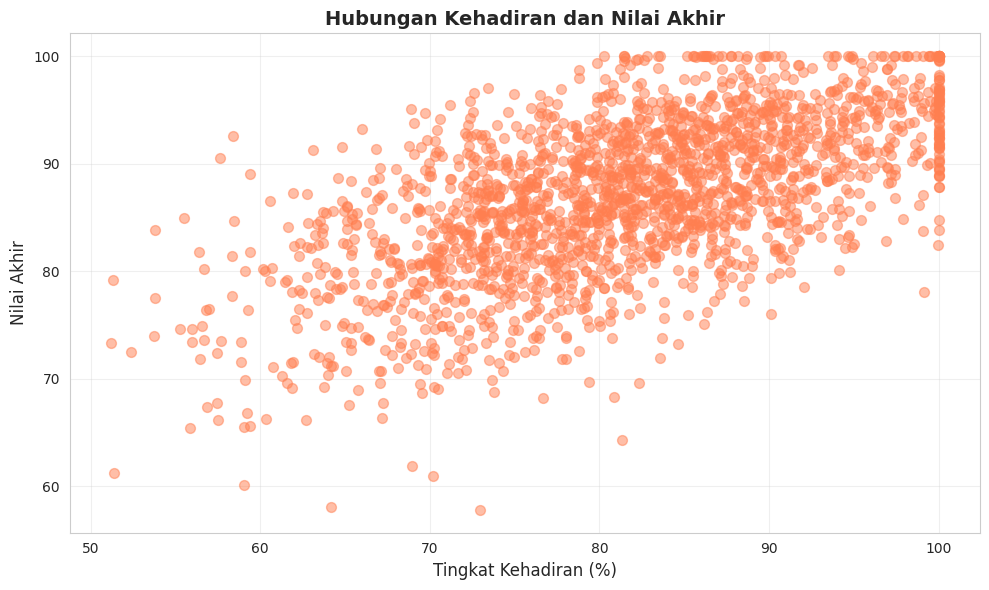

Korelasi Pearson: 0.612
Interpretasi: Hubungan positif sedang


In [4]:
# RUN-NOW: Jalankan sel ini apa adanya.
plt.figure(figsize=(10, 6))
plt.scatter(df["attendance_rate"], df["final_grade"], alpha=0.5, s=50, color="coral")
plt.xlabel("Tingkat Kehadiran (%)", fontsize=12)
plt.ylabel("Nilai Akhir", fontsize=12)
plt.title("Hubungan Kehadiran dan Nilai Akhir", fontsize=14, fontweight="bold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Hitung korelasi
corr = df["attendance_rate"].corr(df["final_grade"])
print(f"Korelasi Pearson: {corr:.3f}")
print(
    f"Interpretasi: Hubungan {'positif' if corr > 0 else 'negatif'} "
    f"{'kuat' if abs(corr) > 0.7 else 'sedang' if abs(corr) > 0.4 else 'lemah'}"
)

### Apa scatter plot ini menunjukkan?

**Pola yang dicari:**
- Tren positif atau negatif?
- Hubungan linear atau non-linear?
- Ada outlier atau cluster?
- Berapa banyak scatter (variasi)?

**Interpretasi caution:**
- ⚠️ Asosiasi ≠ Kausalitas!
- Mungkin ada confounder (variabel ketiga) yang pengaruhi keduanya
- Strength asosiasi diukur dengan korelasi (kita akan pelajari di notebook 5)

## Chart 4: Bar chart - Distribusi internet access

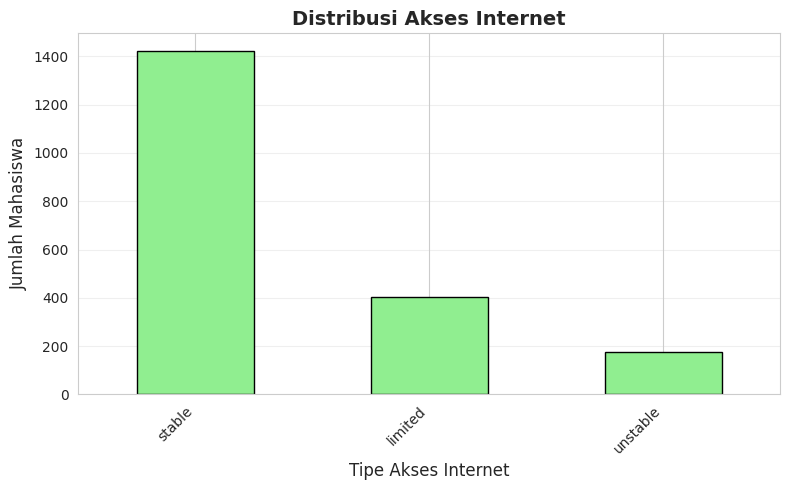

Distribusi Akses Internet:
internet_access
stable      71.2
limited     20.1
unstable     8.7
Name: count, dtype: float64


In [5]:
# RUN-NOW: Jalankan sel ini apa adanya.
internet_counts = df["internet_access"].value_counts()

plt.figure(figsize=(8, 5))
internet_counts.plot(kind="bar", color="lightgreen", edgecolor="black")
plt.xlabel("Tipe Akses Internet", fontsize=12)
plt.ylabel("Jumlah Mahasiswa", fontsize=12)
plt.title("Distribusi Akses Internet", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Tambah persentase
print("Distribusi Akses Internet:")
print((internet_counts / internet_counts.sum() * 100).round(2))

### Apa bar chart ini menunjukkan?

**Untuk data kategoris:**
- Frekuensi setiap kategori
- Kategori mana paling/paling sedikit?
- Apakah distribusi balanced atau skewed?

**Interpretasi caution:**
- Bar chart menunjukkan COUNT, bukan rate
- Jika total sampel berbeda, perlu normalisasi ke persentase

## Chart 5: Boxplot tambahan - final_grade by internet access

/tmp/ipykernel_5912/2158550833.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='internet_access', y='final_grade', palette='Set3')


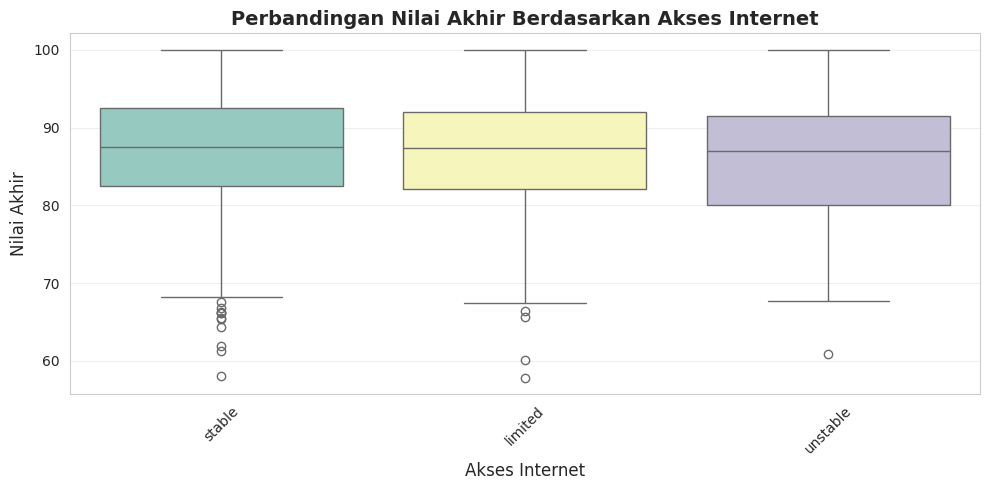

In [6]:
# RUN-NOW: Jalankan sel ini apa adanya.
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='internet_access', y='final_grade', palette='Set3')
plt.xlabel('Akses Internet', fontsize=12)
plt.ylabel('Nilai Akhir', fontsize=12)
plt.title('Perbandingan Nilai Akhir Berdasarkan Akses Internet', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Kesimpulan dari EDA

In [7]:
# RUN-NOW: Jalankan sel ini apa adanya.
print("""
📊 RINGKASAN EXPLORATORY DATA ANALYSIS
=====================================

1. DISTRIBUSI NILAI AKHIR:
   - Median: {:.2f}, Mean: {:.2f}
   - Ada outlier? [Lihat histogram]

2. PERBEDAAN ANTAR PROGRAM:
   - Program mana dengan rata-rata tertinggi? [Lihat boxplot]
   - Variasi sama atau berbeda? [Lihat lebar kotak]

3. HUBUNGAN KEHADIRAN & NILAI:
   - Ada asosiasi positif (korelasi > 0)? [Lihat scatter]
   - Berapa kuat? [Lihat korelasi]

4. FAKTOR LAIN (INTERNET ACCESS):
   - Apakah akses internet berkaitan dengan nilai?
   - Kelompok mana dengan nilai tertinggi/terendah?

PERTANYAAN UNTUK NOTEBOOK BERIKUTNYA:
- Apakah kehadiran adalah prediktor nilai terbaik?
- Atau ada variabel lain yang lebih penting?
- Bagaimana cara mengukur pengaruh secara kuantitatif?
""".format(df['final_grade'].median(), df['final_grade'].mean()))


📊 RINGKASAN EXPLORATORY DATA ANALYSIS

1. DISTRIBUSI NILAI AKHIR:
   - Median: 87.34, Mean: 86.91
   - Ada outlier? [Lihat histogram]

2. PERBEDAAN ANTAR PROGRAM:
   - Program mana dengan rata-rata tertinggi? [Lihat boxplot]
   - Variasi sama atau berbeda? [Lihat lebar kotak]

3. HUBUNGAN KEHADIRAN & NILAI:
   - Ada asosiasi positif (korelasi > 0)? [Lihat scatter]
   - Berapa kuat? [Lihat korelasi]

4. FAKTOR LAIN (INTERNET ACCESS):
   - Apakah akses internet berkaitan dengan nilai?
   - Kelompok mana dengan nilai tertinggi/terendah?

PERTANYAAN UNTUK NOTEBOOK BERIKUTNYA:
- Apakah kehadiran adalah prediktor nilai terbaik?
- Atau ada variabel lain yang lebih penting?
- Bagaimana cara mengukur pengaruh secara kuantitatif?



## Tugas Anda

Buat satu visualisasi tambahan:

1. Pilih dua variabel numerik atau kategoris yang Anda ingin explore

Previous GPA dan Final Grade

2. Pilih tipe chart yang tepat (histogram, scatter, boxplot, bar)

Scatter Plot

3. Buat chart dengan label dan title yang jelas

Hubungan Previous Gpa dengan Nilai Akhir

4. Tulis interpretasi 2-3 baris

Scatter plot menunjukkan adanya hubungan positif antara Previous GPA dan Final Grade, di mana mahasiswa dengan IPK sebelumnya yang lebih tinggi cenderung memperoleh nilai akhir yang lebih baik. Nilai korelasi Pearson sebesar 0.682 menandakan hubungan positif dengan kekuatan sedang menuju kuat. Meskipun demikian, sebaran titik yang masih cukup luas menunjukkan bahwa nilai akhir juga dipengaruhi oleh faktor lain selain IPK sebelumnya.


Kode awal:

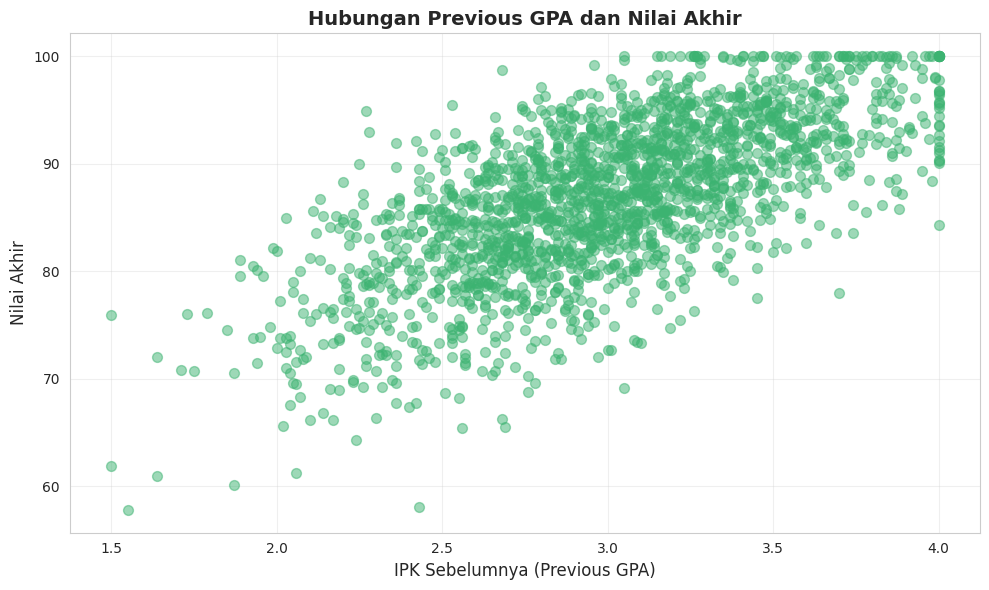

Korelasi Pearson: 0.682
Interpretasi: Hubungan positif sedang


In [8]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["previous_gpa"],
    df["final_grade"],
    alpha=0.5,
    s=50,
    color="mediumseagreen"
)

plt.xlabel("IPK Sebelumnya (Previous GPA)", fontsize=12)
plt.ylabel("Nilai Akhir", fontsize=12)
plt.title(
    "Hubungan Previous GPA dan Nilai Akhir",
    fontsize=14,
    fontweight="bold"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Hitung korelasi Pearson
corr = df["previous_gpa"].corr(df["final_grade"])

print(f"Korelasi Pearson: {corr:.3f}")

print(
    f"Interpretasi: Hubungan {'positif' if corr > 0 else 'negatif'} "
    f"{'kuat' if abs(corr) > 0.7 else 'sedang' if abs(corr) > 0.4 else 'lemah'}"
)   

## Langkah berikutnya

✓ Anda sudah membuat visualisasi awal dan mengenali pola data

→ Notebook berikutnya (`04_descriptive_statistics.ipynb`): Hitung statistik deskriptif secara rinci dengan perbandingan grup.